# 03 · Proof of Concept: Customer Email Classifier (NLP)
The WISMO recommendation depends on one capability: **recognising a "where is my shipment?" email automatically**, so it can be answered from tracking data while everything else is routed to a person.

This notebook tests whether that is feasible with the client's own inbox history:

1. Keyword-rule baseline (what a team would build in Excel/Outlook rules)
2. TF-IDF + logistic regression classifier
3. Confidence threshold for safe automation (precision first)
4. Label the ~4% of tickets that agents never tagged

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

FIG = Path("../reports/figures")
BLUE, ORANGE, GRAY, MUTED = "#2a78d6", "#eb6834", "#c9c8c3", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 11})

tickets = pd.read_csv("../data/processed/cs_tickets_clean.csv")
labeled = tickets.dropna(subset=["category"]).copy()
unlabeled = tickets[tickets["category"].isna()].copy()
print(f"Labelled: {len(labeled):,} | Unlabelled: {len(unlabeled):,}")
labeled["category"].value_counts(normalize=True).round(3)

Labelled: 24,954 | Unlabelled: 1,046


category
WISMO                 0.456
Delivery exception    0.151
Booking change        0.139
Other                 0.112
Billing question      0.080
Damage / claim        0.062
Name: proportion, dtype: float64

In [2]:
labeled[["message_text", "category"]].sample(6, random_state=7)

,message_text,category
15887,Urgent: Please advise delivery status of KT181...,WISMO
17692,Can we add 8 more pallets to booking KT2603268...,Booking change
10165,Claim follow-up for KT68942196: any update on ...,Damage / claim
6783,"Hello, Please change the delivery date of KT35...",Booking change
20173,"Dear CS, Hi, could you tell me whee shipment K...",WISMO
13312,"Hi, could you tell me where shipment KT5301214...",WISMO


Note: about 3% of historical labels are wrong (agents tagging in a hurry) and ~12% of emails mix two topics. A realistic ceiling is therefore below 100%.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    labeled["message_text"], labeled["category"], test_size=0.2, stratify=labeled["category"], random_state=42)
print(f"Train {len(X_train):,} / Test {len(X_test):,}")

Train 19,963 / Test 4,991


## 1. Baseline: keyword rules

In [4]:
RULES = [
    ("Damage / claim", ["damaged", "crushed", "claim", "wet on arrival"]),
    ("Billing question", ["invoice", "billed", "surcharge", "credit note"]),
    ("Delivery exception", ["returned", "missed", "only", "nobody", "redeliver"]),
    ("Booking change", ["change", "cancel", "add", "update the consignee"]),
    ("WISMO", ["where", "status", "tracking", "eta", "out for delivery", "left your"]),
]
def rule_classify(text):
    t = text.lower()
    for label, kws in RULES:
        if any(k in t for k in kws):
            return label
    return "Other"
rule_pred = X_test.map(rule_classify)
print(f"Rules  accuracy {accuracy_score(y_test, rule_pred):.3f} | macro-F1 {f1_score(y_test, rule_pred, average='macro'):.3f}")

Rules  accuracy 0.895 | macro-F1 0.871


## 2. TF-IDF + logistic regression
Word n-grams capture phrases ("out for delivery"); character n-grams make the model robust to typos and shipment IDs.

In [5]:
model = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True)),
    LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced"),
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(f"Model  accuracy {accuracy_score(y_test, pred):.3f} | macro-F1 {f1_score(y_test, pred, average='macro'):.3f}\n")
print(classification_report(y_test, pred, digits=3))

Model  accuracy 0.974 | macro-F1 0.965

                    precision    recall  f1-score   support

  Billing question      0.974     0.947     0.961       399
    Booking change      0.978     0.961     0.969       692
    Damage / claim      0.950     0.922     0.936       309
Delivery exception      0.980     0.974     0.977       755
             Other      0.972     0.950     0.961       558
             WISMO      0.973     0.995     0.984      2278

          accuracy                          0.974      4991
         macro avg      0.971     0.958     0.965      4991
      weighted avg      0.974     0.974     0.973      4991



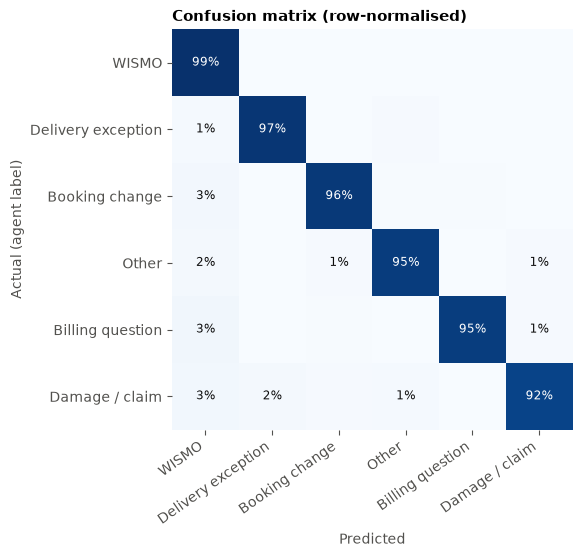

In [6]:
labels = labeled["category"].value_counts().index.tolist()
cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] >= 0.01:
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=8.5,
                    color="white" if cm[i, j] > 0.6 else "#0b0b0b")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual (agent label)")
ax.set_title("Confusion matrix (row-normalised)", loc="left")
ax.spines[["left", "bottom"]].set_visible(False)
fig.savefig(FIG / "06_confusion_matrix.png", dpi=160, bbox_inches="tight")

## 3. Safe automation: only act when the model is confident
For customers, a wrong automatic reply is worse than a slow human one. So an email is auto-handled as WISMO only when the predicted probability passes a threshold, and everything else goes to an agent. Two things matter when choosing that threshold:

- **Precision**: how many auto-handled emails are truly WISMO.
- **Mixed-topic emails**: an email that asks for status *and* raises a damage claim must reach a person, even if it is mostly WISMO.

In [7]:
proba = model.predict_proba(X_test)
wi = list(model.classes_).index("WISMO")
p_w = proba[:, wi]
is_w = (y_test == "WISMO").values
mixed = X_test.str.contains("Also,", regex=False).values   # second topic appended in the email
rows = []
for th in np.round(np.arange(0.50, 0.991, 0.01), 2):
    sel = p_w >= th
    rows.append({"threshold": th, "precision": is_w[sel].mean() if sel.any() else np.nan,
                 "coverage_of_wismo": (sel & is_w).sum() / is_w.sum(),
                 "mixed_topic_auto_handled": (sel & mixed & is_w).sum() / max((mixed & is_w).sum(), 1)})
curve = pd.DataFrame(rows)
curve[curve["threshold"].isin([0.5, 0.7, 0.8, 0.85, 0.9, 0.95])].round(3)

,threshold,precision,coverage_of_wismo,mixed_topic_auto_handled
0,0.50,0.974,0.995,0.982
20,0.70,0.975,0.974,0.835
30,0.80,0.974,0.946,0.647
35,0.85,0.973,0.903,0.451
40,0.90,0.974,0.803,0.241
45,0.95,0.975,0.458,0.027


Precision stays at ~97.4% at every threshold. The ceiling comes from the ~3% of agent labels that are wrong, not from the model. What the threshold really controls is how many **mixed-topic** emails slip into automation. We pick the lowest threshold that keeps at least 75% of mixed-topic WISMO emails with a human.

Chosen threshold: 0.90 -> precision 97.4% | WISMO auto-handled 80.3% | mixed-topic auto-handled 24.1%


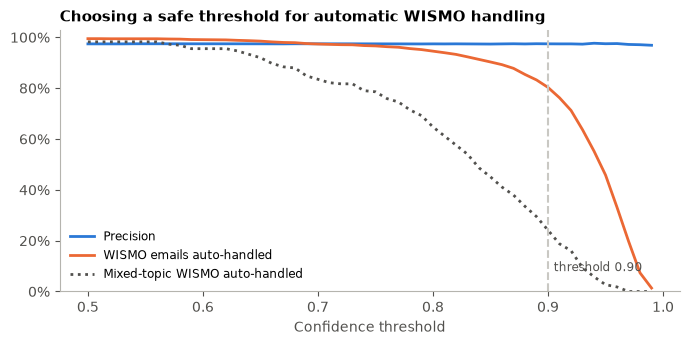

In [8]:
TH = float(curve.loc[curve["mixed_topic_auto_handled"] <= 0.25, "threshold"].min())
chosen = curve[curve["threshold"] == TH].iloc[0]
print(f"Chosen threshold: {TH:.2f} -> precision {chosen['precision']:.1%} | "
      f"WISMO auto-handled {chosen['coverage_of_wismo']:.1%} | mixed-topic auto-handled {chosen['mixed_topic_auto_handled']:.1%}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(curve["threshold"], curve["precision"], color=BLUE, lw=2, label="Precision")
ax.plot(curve["threshold"], curve["coverage_of_wismo"], color=ORANGE, lw=2, label="WISMO emails auto-handled")
ax.plot(curve["threshold"], curve["mixed_topic_auto_handled"], color=MUTED, lw=2, ls=":", label="Mixed-topic WISMO auto-handled")
ax.axvline(TH, color=GRAY, lw=1.5, ls="--")
ax.text(TH + 0.005, 0.08, f"threshold {TH:.2f}", color=MUTED, fontsize=8.5)
ax.set_xlabel("Confidence threshold"); ax.set_ylim(0, 1.03)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_title("Choosing a safe threshold for automatic WISMO handling", loc="left")
fig.savefig(FIG / "07_threshold.png", dpi=160, bbox_inches="tight")

## 4. Label the untagged tickets

In [9]:
unlabeled["predicted_category"] = model.predict(unlabeled["message_text"])
unlabeled["confidence"] = model.predict_proba(unlabeled["message_text"]).max(axis=1).round(3)
print(unlabeled["predicted_category"].value_counts())
unlabeled[["message_text", "predicted_category", "confidence"]].head(6)

predicted_category
WISMO                 486
Delivery exception    158
Booking change        156
Other                 106
Billing question       79
Damage / claim         61
Name: count, dtype: int64


,message_text,predicted_category,confidence
39,"Dear CS, Can you share your new rate card for ...",Other,0.992
71,Re: Is KT63239088 out for delivery today? Need...,WISMO,0.969
116,urgent: delivery of kt74443288 missed the time...,Delivery exception,0.982
122,"Hi team, Following up again on KT26303841 - no...",WISMO,0.936
169,"Hi team, Please advise delivery status of KT82...",WISMO,0.933
219,driver reported nobody at the saitama site for...,Delivery exception,0.988


## 5. What this means for the business case

In [10]:
wismo_year = (tickets["category"] == "WISMO").sum() + (unlabeled["predicted_category"] == "WISMO").sum()
auto = wismo_year * chosen["coverage_of_wismo"]
print(f"WISMO emails per year (incl. untagged): {wismo_year:,}")
print(f"Auto-handled at threshold {TH:.2f}      : {auto:,.0f} ({chosen['coverage_of_wismo']:.0%})")
print("Assumed in ROI notebook               : 60% of WISMO time removed")

WISMO emails per year (incl. untagged): 11,877
Auto-handled at threshold 0.90      : 9,536 (80%)
Assumed in ROI notebook               : 60% of WISMO time removed


**Conclusion.** A simple, explainable model trained on the client's own inbox clearly beats keyword rules (macro-F1 0.97 vs 0.87). With a conservative threshold it can auto-handle roughly four in five WISMO emails at ~97% precision while keeping most mixed-topic emails with a person. That covers the 60% assumption in the ROI before counting the second lever, proactive notifications, which stops many of these emails from being sent at all. Remaining emails go to agents with a suggested category, which speeds up routing.

**Next step in a real engagement:** pilot on live email for 4 weeks in "suggest" mode (agent approves each reply), measure precision on fresh data, then switch on auto-send for high-confidence WISMO only.